# Tugas Sequential Pattern Analysis — Online Retail

**Muhammad Irzam Hafis Fabiansyah — 5054251024**

Di tugas ini kita cari pola urutan barang yang dibeli tiap pelanggan di dataset *Online Retail* (UCI) dengan algoritma **PrefixSpan**. Hasilnya dinilai pakai **support** dan **confidence**.

## 1. Import Dataset

In [1]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from prefixspan import PrefixSpan

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_excel("../scratchpad/week5/data/Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 2. Eksplorasi dan Pembersihan Data

Kolom yang dipakai: **`CustomerID`** (siapa pembelinya), **`InvoiceDate`** (kapan beli), **`InvoiceNo`** (satu transaksi), dan **`Description`** (nama barang). `Quantity` dipakai untuk membuang baris yang tidak valid.

In [5]:
print("Missing value per kolom:")
print(df.isna().sum())
print("\nInvoice dibatalkan (diawali 'C'):", df["InvoiceNo"].astype(str).str.startswith("C").sum(), "baris")
print("Quantity <= 0:", (df["Quantity"] <= 0).sum(), "baris")

Missing value per kolom:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Invoice dibatalkan (diawali 'C'): 9288 baris
Quantity <= 0: 10624 baris


In [6]:
def ringkas(d):
    return {"baris": len(d), "invoice unik": d["InvoiceNo"].nunique(),
            "pelanggan unik": d["CustomerID"].nunique(), "produk unik": d["Description"].nunique()}

log = [("Data awal", ringkas(df))]

d = df.dropna(subset=["Description"])
log.append(("Hapus Description kosong", ringkas(d)))

d = d[~d["InvoiceNo"].astype(str).str.startswith("C")]
log.append(("Hapus invoice dibatalkan ('C')", ringkas(d)))

d = d[d["Quantity"] > 0]
log.append(("Hapus Quantity <= 0", ringkas(d)))

d = d.dropna(subset=["CustomerID"])
log.append(("Hapus CustomerID kosong", ringkas(d)))

# Rapikan spasi berlebih pada Description agar produk yang sama tidak terpecah
d = d.assign(Description=d["Description"].str.strip(), CustomerID=d["CustomerID"].astype(int))
log.append(("Rapikan spasi Description", ringkas(d)))
pd.DataFrame({k: v for k, v in log}).T

,baris,invoice unik,pelanggan unik,produk unik
Data awal,541909,25900,4372,4223
Hapus Description kosong,540455,24446,4372,4223
Hapus invoice dibatalkan ('C'),531167,20610,4339,4207
Hapus Quantity <= 0,530693,20136,4339,4077
Hapus CustomerID kosong,397924,18536,4339,3877
Rapikan spasi Description,397924,18536,4339,3866


Beberapa baris sebenarnya bukan barang, tapi biaya seperti `POSTAGE`, `Manual`, dan `AMAZON FEE`. Ini tidak berguna untuk pola belanja, jadi ikut dibuang.

In [7]:
non_produk = ["POST", "DOT", "M", "D", "S", "B", "CRUK", "C2", "BANK CHARGES", "AMAZONFEE", "PADS"]
mask = d["StockCode"].astype(str).isin(non_produk)
print("Baris non-produk yang dibuang:", mask.sum())
print(d[mask]["Description"].value_counts().head(10))
clean = d[~mask].copy()
log.append(("Hapus item non-produk (postage, fee, dll)", ringkas(clean)))
ringkasan = pd.DataFrame({k: v for k, v in log}).T
ringkasan

Baris non-produk yang dibuang: 1554
Description
POSTAGE                       1099
Manual                         290
CARRIAGE                       133
DOTCOM POSTAGE                  16
Bank Charges                    12
PADS TO MATCH ALL CUSHIONS       4
Name: count, dtype: int64


,baris,invoice unik,pelanggan unik,produk unik
Data awal,541909,25900,4372,4223
Hapus Description kosong,540455,24446,4372,4223
Hapus invoice dibatalkan ('C'),531167,20610,4339,4207
Hapus Quantity <= 0,530693,20136,4339,4077
Hapus CustomerID kosong,397924,18536,4339,3877
Rapikan spasi Description,397924,18536,4339,3866
"Hapus item non-produk (postage, fee, dll)",396370,18405,4335,3860


In [8]:
print(f"Sebelum: {len(df):,} baris, {df['InvoiceNo'].nunique():,} invoice, {df['CustomerID'].nunique():,} pelanggan")
print(f"Sesudah: {len(clean):,} baris, {clean['InvoiceNo'].nunique():,} invoice, {clean['CustomerID'].nunique():,} pelanggan")

Sebelum: 541,909 baris, 25,900 invoice, 4,372 pelanggan
Sesudah: 396,370 baris, 18,405 invoice, 4,335 pelanggan


### Eksplorasi singkat data bersih

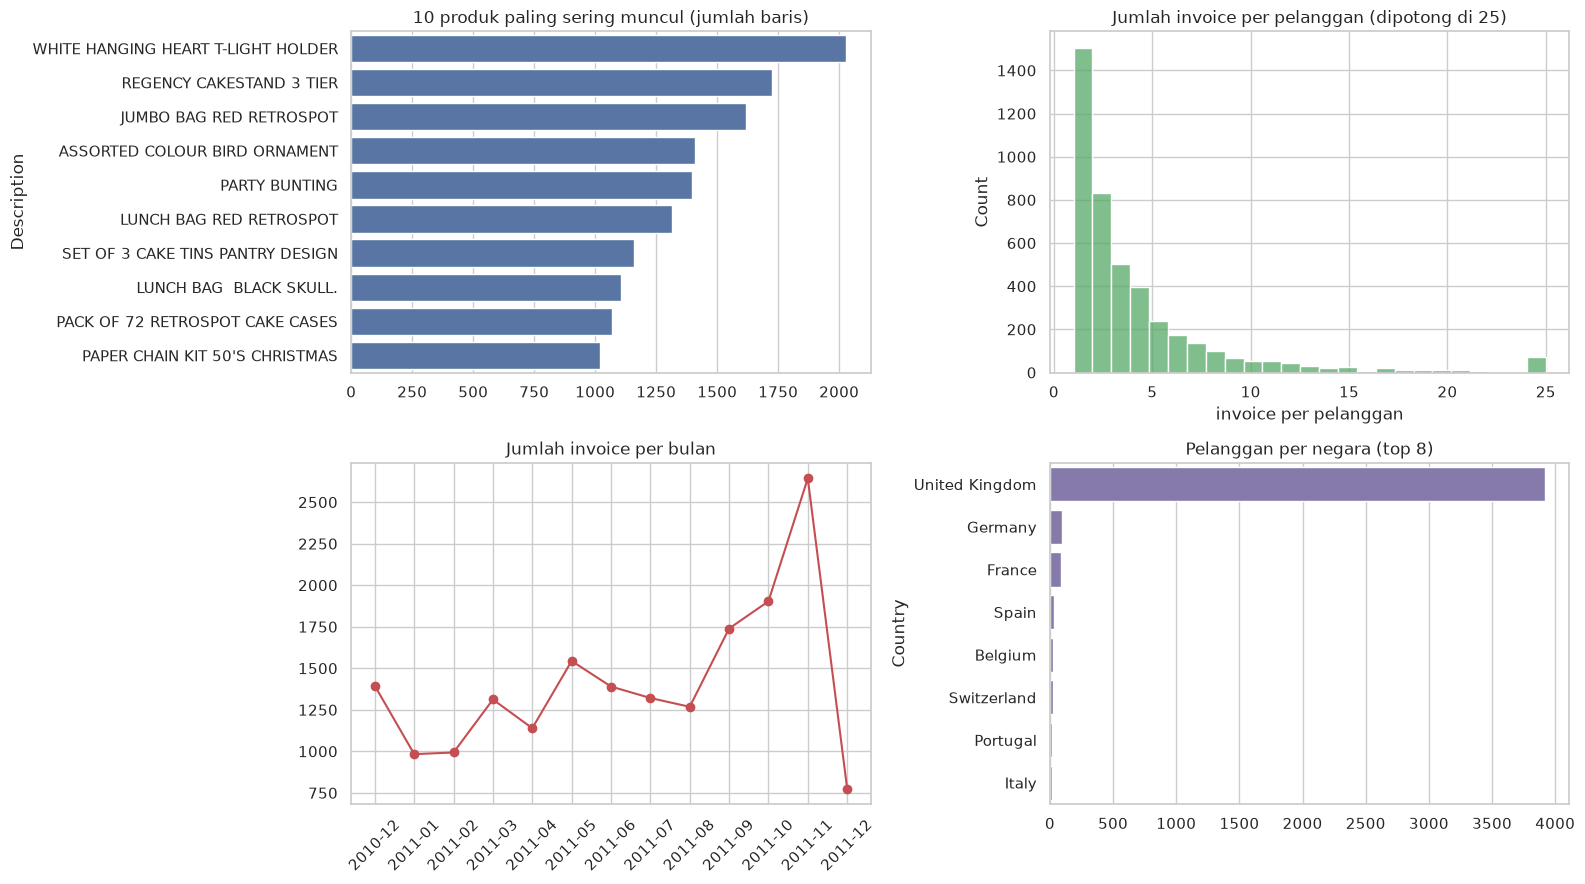

count    4335.000000
mean        4.245675
std         7.636337
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       206.000000
Name: InvoiceNo, dtype: float64
Pelanggan dengan >= 2 invoice: 2829


In [9]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))

top = clean["Description"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, ax=ax[0, 0], color="#4C72B0")
ax[0, 0].set_title("10 produk paling sering muncul (jumlah baris)")

inv_per_cust = clean.groupby("CustomerID")["InvoiceNo"].nunique()
sns.histplot(inv_per_cust.clip(upper=25), bins=25, ax=ax[0, 1], color="#55A868")
ax[0, 1].set_title("Jumlah invoice per pelanggan (dipotong di 25)")
ax[0, 1].set_xlabel("invoice per pelanggan")

bulan = clean.groupby(clean["InvoiceDate"].dt.to_period("M"))["InvoiceNo"].nunique()
ax[1, 0].plot(bulan.index.astype(str), bulan.values, marker="o", color="#C44E52")
ax[1, 0].set_title("Jumlah invoice per bulan"); ax[1, 0].tick_params(axis="x", rotation=45)

neg = clean.groupby("Country")["CustomerID"].nunique().sort_values(ascending=False).head(8)
sns.barplot(x=neg.values, y=neg.index, ax=ax[1, 1], color="#8172B2")
ax[1, 1].set_title("Pelanggan per negara (top 8)")
plt.tight_layout(); plt.show()
print(inv_per_cust.describe())
print("Pelanggan dengan >= 2 invoice:", (inv_per_cust >= 2).sum())

## 3. Persiapan Data untuk Sequential Pattern Mining

Data diurutkan per `CustomerID` lalu `InvoiceDate`. Barang dalam satu invoice dijadikan satu itemset (barang yang sama dalam satu invoice dihitung sekali). Tiap pelanggan jadi satu sequence, yaitu daftar itemset menurut urutan waktu (*list of list*).

In [10]:
clean = clean.sort_values(["CustomerID", "InvoiceDate", "InvoiceNo"], kind="stable")

keranjang = clean.groupby(["CustomerID", "InvoiceNo"], sort=False)["Description"].apply(lambda s: list(dict.fromkeys(s)))

sequence_itemset = {}          # CustomerID -> [itemset_invoice_1, itemset_invoice_2, ...]
for (cid, inv), items in keranjang.items():
    sequence_itemset.setdefault(cid, []).append(items)

print("Jumlah sequence (pelanggan):", len(sequence_itemset))
cid0 = next(iter(sequence_itemset))
print(f"\nContoh pelanggan {cid0}: {len(sequence_itemset[cid0])} invoice")
for k, its in enumerate(sequence_itemset[cid0][:3], 1):
    print(f"  itemset {k} ({len(its)} item):", its[:3], "...")

Jumlah sequence (pelanggan): 4335

Contoh pelanggan 12346: 1 invoice
  itemset 1 (1 item): ['MEDIUM CERAMIC TOP STORAGE JAR'] ...


Library `prefixspan` hanya menerima daftar barang, bukan daftar itemset. Jadi itemset tiap invoice digabung berurutan sesuai waktu invoice. Urutan antar invoice tetap terjaga, tapi barang **dalam satu invoice** ikut berurutan sesuai baris di data. Akibatnya, sebagian pola bisa saja berasal dari satu invoice yang sama.

In [11]:
sequences = [[item for inv in invoices for item in inv] for invoices in sequence_itemset.values()]

panjang = pd.Series([len(s) for s in sequences])
print("Contoh sequence pertama (10 item pertama):", sequences[0][:10])
print("\nPanjang sequence (jumlah item):")
print(panjang.describe())

Contoh sequence pertama (10 item pertama): ['MEDIUM CERAMIC TOP STORAGE JAR']

Panjang sequence (jumlah item):
count    4335.000000
mean       89.082814
std       221.368589
min         1.000000
25%        17.000000
50%        40.000000
75%        97.000000
max      7466.000000
dtype: float64


## 4. Penerapan Algoritma PrefixSpan

Kita mulai dari `min_support = 0,01` (sekitar 44 pelanggan). Ternyata terlalu kecil: polanya terlalu banyak dan perhitungannya tidak selesai dalam waktu wajar. Ini perbandingan beberapa nilai support.

In [12]:
import time
n = len(sequences)

def jalankan(min_support, maxlen=None):
    ps = PrefixSpan(sequences)
    if maxlen:
        ps.maxlen = maxlen
    t = time.time()
    hasil = ps.frequent(math.ceil(min_support * n))
    return hasil, time.time() - t

baris = []
for ms, ml in [(0.01, 2), (0.05, None), (0.03, None), (0.02, None)]:
    hasil, dur = jalankan(ms, ml)
    baris.append({"min_support": ms, "batas panjang": ml or "tanpa batas",
                  "min_count pelanggan": math.ceil(ms * n), "jumlah pola": len(hasil), "waktu (detik)": round(dur, 1)})
    if (ms, ml) == (0.02, None):
        patterns = hasil
pd.DataFrame(baris)

,min_support,batas panjang,min_count pelanggan,jumlah pola,waktu (detik)
0,0.01,2,44,27125,10.8
1,0.05,tanpa batas,217,305,4.1
2,0.03,tanpa batas,131,1328,12.6
3,0.02,tanpa batas,87,5991,44.8


- `min_support = 0,01`: pola sepanjang ≤ 2 saja sudah puluhan ribu. Tanpa batas panjang, perhitungan tidak selesai dalam beberapa menit.
- `min_support = 0,05`: hanya 305 pola, kebanyakan barang yang paling populer.
- **`min_support = 0,02`** (minimal 87 pelanggan) dipilih: polanya ribuan tapi masih bisa dibaca, dan perhitungannya cukup cepat.

## 5. Evaluasi Pola Berurutan

**Support** = berapa persen pelanggan yang urutan belinya mengandung pola itu. **Confidence** = dari pelanggan yang sudah membeli bagian awal pola, berapa persen yang lalu membeli barang terakhirnya. Rumusnya support(pola lengkap) / support(pola tanpa barang terakhir). Pola satu barang tidak punya confidence.

In [13]:
support_count = {tuple(p): c for c, p in patterns}

def confidence(p):
    return support_count[p] / support_count[p[:-1]] if len(p) > 1 else np.nan

hasil = pd.DataFrame({
    "pola": [" → ".join(p) for p in support_count],
    "panjang": [len(p) for p in support_count],
    "pelanggan": list(support_count.values()),
})
hasil["support"] = hasil["pelanggan"] / n
hasil["confidence"] = [confidence(p) for p in support_count]
hasil = hasil.sort_values(["support", "panjang"], ascending=[False, False]).reset_index(drop=True)
print("Jumlah pola:", len(hasil))
print(hasil["panjang"].value_counts().sort_index())
hasil.head(10)

Jumlah pola: 5991
panjang
1    1044
2    2805
3    1744
4     397
5       1
Name: count, dtype: int64


,pola,panjang,pelanggan,support,confidence
0,REGENCY CAKESTAND 3 TIER,1,881,0.203230,NaN
1,WHITE HANGING HEART T-LIGHT HOLDER,1,856,0.197463,NaN
2,PARTY BUNTING,1,708,0.163322,NaN
3,ASSORTED COLOUR BIRD ORNAMENT,1,678,0.156401,NaN
4,SET OF 3 CAKE TINS PANTRY DESIGN,1,640,0.147636,NaN
5,PACK OF 72 RETROSPOT CAKE CASES,1,635,0.146482,NaN
6,JUMBO BAG RED RETROSPOT,1,635,0.146482,NaN
7,PAPER CHAIN KIT 50'S CHRISTMAS,1,613,0.141407,NaN
8,NATURAL SLATE HEART CHALKBOARD,1,587,0.135409,NaN
9,BAKING SET 9 PIECE RETROSPOT,1,581,0.134025,NaN


In [14]:
berurutan = hasil[hasil["panjang"] >= 2]
print("Pola berurutan (panjang >= 2):", len(berurutan))
berurutan.head(15)

Pola berurutan (panjang >= 2): 4947


,pola,panjang,pelanggan,support,confidence
37,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,2,405,0.093426,0.473131
89,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,2,330,0.076125,0.374574
110,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.071972,0.491339
133,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOUR BIRD ORNAMENT,2,291,0.067128,0.429204
151,PARTY BUNTING → PARTY BUNTING,2,280,0.064591,0.395480
157,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,276,0.063668,0.518797
185,PARTY BUNTING → SPOTTY BUNTING,2,255,0.058824,0.360169
189,REGENCY CAKESTAND 3 TIER → ROSES REGENCY TEACUP AND SAUCER,2,252,0.058131,0.286039
192,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,2,251,0.057901,0.471805
195,LUNCH BAG CARS BLUE → LUNCH BAG RED RETROSPOT,2,250,0.057670,0.521921


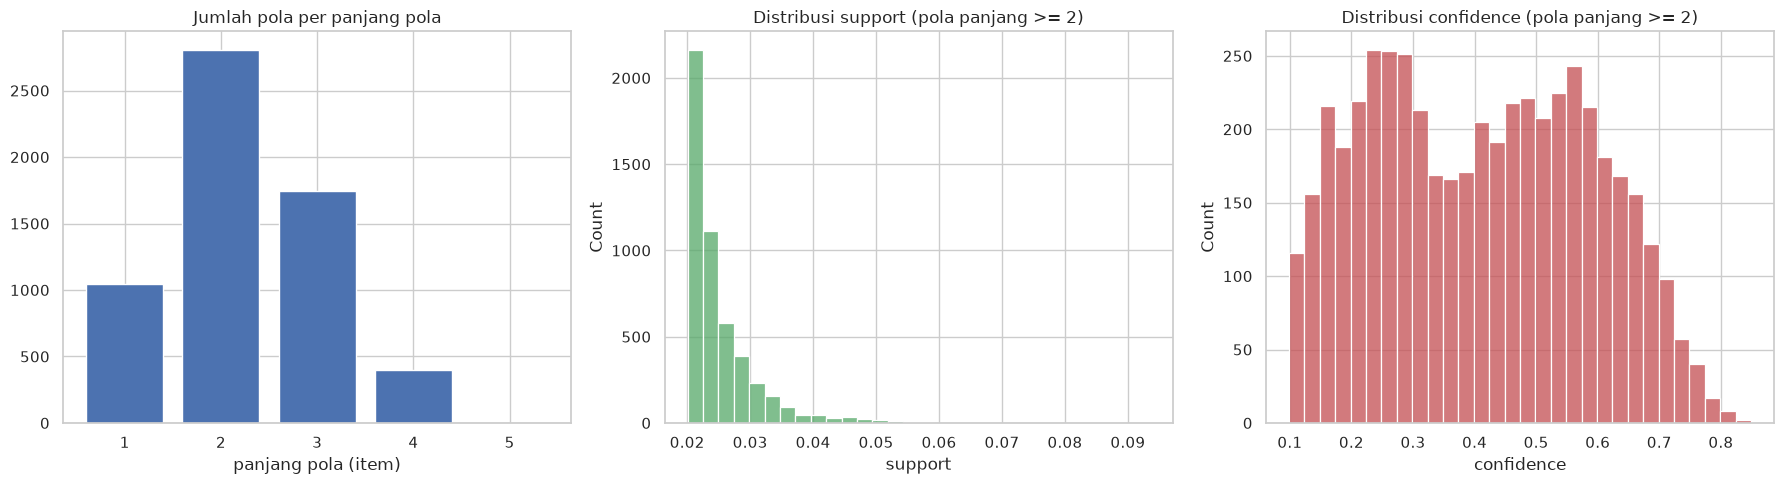

,support,confidence
count,4947.000000,4947.000000
mean,0.025001,0.410156
std,0.005945,0.175740
min,0.020069,0.098751
25%,0.021223,0.257614
50%,0.023068,0.410480
75%,0.026759,0.556026
max,0.093426,0.848684


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].bar(hasil["panjang"].value_counts().sort_index().index, hasil["panjang"].value_counts().sort_index().values, color="#4C72B0")
ax[0].set_title("Jumlah pola per panjang pola"); ax[0].set_xlabel("panjang pola (item)")
sns.histplot(berurutan["support"], bins=30, ax=ax[1], color="#55A868")
ax[1].set_title("Distribusi support (pola panjang >= 2)")
sns.histplot(berurutan["confidence"], bins=30, ax=ax[2], color="#C44E52")
ax[2].set_title("Distribusi confidence (pola panjang >= 2)")
plt.tight_layout(); plt.show()
berurutan[["support", "confidence"]].describe()

### Tiga pola terbaik berdasarkan support

Pola satu barang cuma menunjukkan barang itu populer, bukan urutan beli. Jadi tiga pola terbaik diambil dari pola **berurutan (minimal 2 barang)** dengan support tertinggi.

In [16]:
top3 = berurutan.head(3)[["pola", "pelanggan", "support", "confidence"]].reset_index(drop=True)
top3.index += 1
top3

,pola,pelanggan,support,confidence
1,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER,405,0.093426,0.473131
2,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER,330,0.076125,0.374574
3,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,312,0.071972,0.491339


Cek ulang: support tiga pola dihitung langsung tanpa PrefixSpan. Angkanya harus sama dengan hasil algoritma.

In [17]:
def memuat(seq, pola):
    it = iter(seq)
    return all(any(x == y for y in it) for x in pola)

for i, baris in top3.iterrows():
    pola = baris["pola"].split(" → ")
    langsung = sum(memuat(s, pola) for s in sequences)
    print(f"#{i}: algoritma = {baris['pelanggan']}, hitung langsung = {langsung}, sama = {langsung == baris['pelanggan']}")

#1: algoritma = 405, hitung langsung = 405, sama = True
#2: algoritma = 330, hitung langsung = 330, sama = True
#3: algoritma = 312, hitung langsung = 312, sama = True


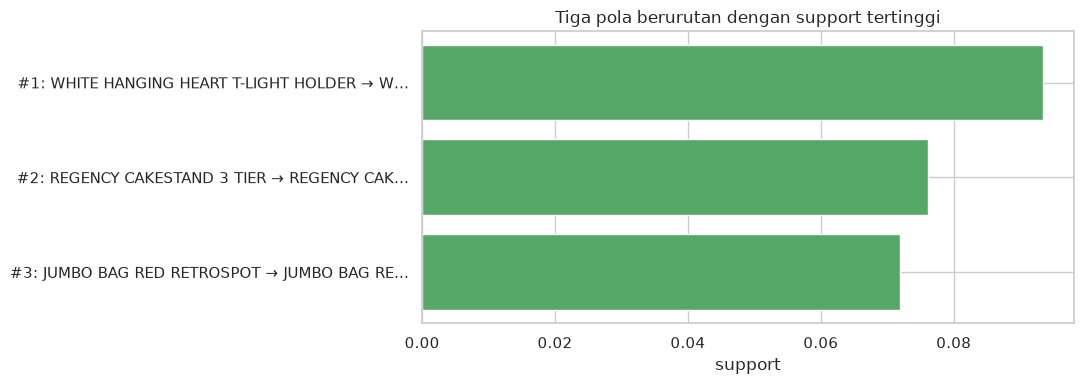

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
lbl = [f"#{i}: {p[:38]}…" if len(p) > 38 else f"#{i}: {p}" for i, p in zip(top3.index, top3["pola"])]
ax.barh(lbl[::-1], top3["support"][::-1], color="#55A868")
ax.set_xlabel("support"); ax.set_title("Tiga pola berurutan dengan support tertinggi")
plt.tight_layout(); plt.show()

### Artinya buat bisnis

| # | Pola berurutan | Pelanggan | Support | Confidence |
|---|----------------|-----------|---------|-----------|
| 1 | WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER | 405 | 9,34% | 47,3% |
| 2 | REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER | 330 | 7,61% | 37,5% |
| 3 | JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT | 312 | 7,20% | 49,1% |

Ketiga pola teratas sama-sama **beli barang yang sama lagi** di invoice yang berbeda. Barang yang sama dalam satu invoice hanya dihitung sekali, jadi pola `X → X` pasti terjadi di dua invoice atau lebih. Ini benar-benar pola urutan, bukan sekadar isi satu keranjang.

1. **White Hanging Heart T-Light Holder.** 405 dari 4.335 pelanggan (9,3%) membelinya dua kali atau lebih. Dari 856 pelanggan yang pernah membelinya, 47,3% beli lagi, hampir separuhnya. Barang ini juga yang paling sering dibeli secara keseluruhan, jadi ia best seller yang sering dibeli ulang.
2. **Regency Cakestand 3 Tier.** Support 7,6%, confidence 37,5%. Pembeli yang kembali mungkin menambah stok untuk dijual lagi atau melengkapi set. Barang seri Regency juga sering dibeli berurutan dengan barang lain, misalnya cakestand lalu Roses Regency Teacup and Saucer (support 5,8%).
3. **Jumbo Bag Red Retrospot.** Support 7,2%, confidence paling tinggi dari ketiganya (49,1%): hampir separuh pembelinya beli lagi. Mungkin barang ini cepat habis atau memang dibeli untuk dijual lagi.

**Saran:** kirim pengingat untuk beli ulang, kasih diskon untuk pembelian banyak atau paket langganan, dan utamakan stok barang yang sering dibeli ulang.

**Catatan:** selain `X → X`, ada juga pola antar barang dalam satu seri, misalnya Party Bunting → Spotty Bunting (support 5,9%, confidence 36%) dan Lunch Bag Red Retrospot → Lunch Bag Black Skull (confidence 47%). Karena sequence digabung jadi satu daftar, pola `X → Y` (barang berbeda) bisa saja berasal dari satu invoice yang sama, jadi bacanya perlu hati-hati.


## 6. Kesimpulan

- **Data:** dari 541.909 baris, 25.900 invoice, dan 4.372 pelanggan, setelah dibersihkan (Description kosong, invoice batal "C", Quantity ≤ 0, CustomerID kosong, dan biaya seperti POSTAGE) tersisa **396.370 baris, 18.405 invoice, 4.335 pelanggan, dan 3.860 produk**. Yang paling banyak dibuang adalah baris tanpa CustomerID (sekitar 133 ribu baris). Sebanyak 2.829 pelanggan (65%) punya minimal 2 invoice; rata-rata 4,2 invoice per pelanggan (median 2).
- **Algoritma:** PrefixSpan dengan `min_support = 0,02` (minimal 87 pelanggan) menemukan **5.991 pola**: 1.044 pola satu barang dan 4.947 pola berurutan (2–5 barang). Support 0,01 tidak dipakai karena polanya terlalu banyak dan perhitungannya tidak selesai. Support 0,05 hanya menyisakan 305 pola.
- **Pola yang paling sering:** **beli barang yang sama lagi** (support tertinggi 9,3% untuk White Hanging Heart T-Light Holder, lalu Regency Cakestand 3 Tier dan Jumbo Bag Red Retrospot). Setelah itu ada urutan antar varian dalam satu seri barang (bunting, lunch bag, paper chain kit).
- **Saran bisnis:** pengingat beli ulang, diskon atau paket langganan untuk barang yang sering dibeli ulang, dan stok yang diutamakan untuk best seller.
- **Keterbatasan:** support pola urutan kecil (rata-rata 2,5%) karena banyak pelanggan cuma belanja sekali dan datanya hanya setahun. Pelanggannya juga campuran eceran dan grosir. Selain itu, `prefixspan` tidak mendukung itemset, jadi barang dalam satu invoice digabung berurutan dan sebagian pola antar barang bisa berasal dari invoice yang sama.
